In [79]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

array([[[200, 200, 200],
        [200, 200, 200],
        [200, 200, 200],
        ...,
        [189, 189, 189],
        [190, 190, 190],
        [190, 190, 190]],

       [[200, 200, 200],
        [199, 199, 199],
        [199, 199, 199],
        ...,
        [190, 190, 190],
        [190, 190, 190],
        [190, 190, 190]],

       [[199, 199, 199],
        [199, 199, 199],
        [199, 199, 199],
        ...,
        [190, 190, 190],
        [190, 190, 190],
        [190, 190, 190]],

       ...,

       [[ 25,  25,  25],
        [ 25,  25,  25],
        [ 27,  27,  27],
        ...,
        [139, 139, 139],
        [122, 122, 122],
        [147, 147, 147]],

       [[ 25,  25,  25],
        [ 25,  25,  25],
        [ 26,  26,  26],
        ...,
        [158, 158, 158],
        [141, 141, 141],
        [168, 168, 168]],

       [[ 25,  25,  25],
        [ 25,  25,  25],
        [ 27,  27,  27],
        ...,
        [151, 151, 151],
        [152, 152, 152],
        [149, 149, 149]]], dtype=uint8)
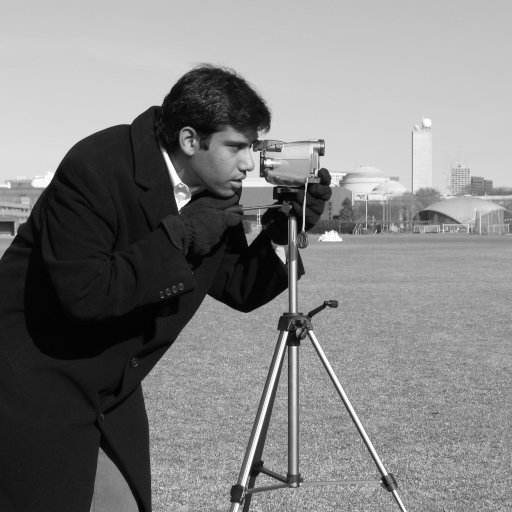

In [80]:
imagem = cv2.cvtColor(data.camera(), cv2.COLOR_BGR2RGB)
imagem

In [81]:
def implot(img, img_filt, nomefiltro, kernelsize):
  plt.figure(figsize=(12, 12))
  plt.subplot(1, 2, 1)
  plt.imshow(img)
  plt.title("Original")
  plt.axis("off")

  plt.subplot(1, 2, 2)
  plt.imshow(img_filt)
  plt.title(f"Filtragem por {nomefiltro}")
  plt.axis("off")
  plt.show()

## 1 - Filtro de média imbutido

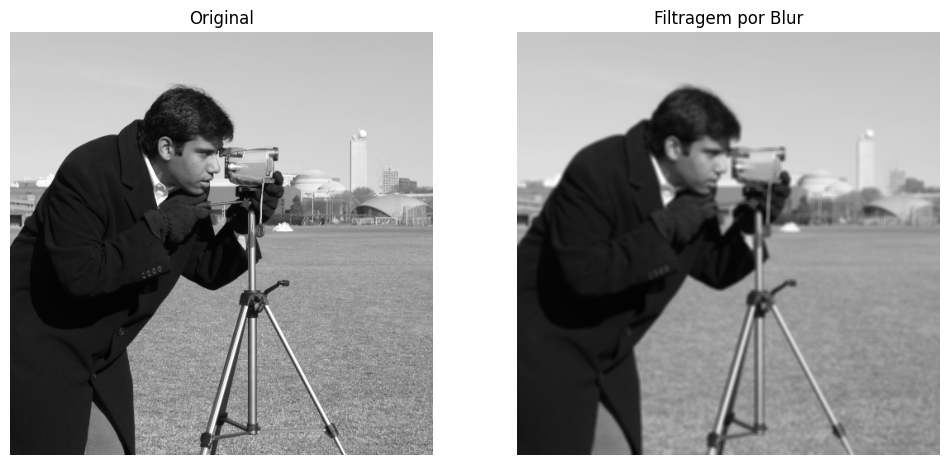

In [82]:
imagem_atenuada = cv2.blur(imagem, (5, 5))
implot(imagem, imagem_atenuada, "Blur", (5, 5))

## 2 - Filtro de média com kernel personalizado

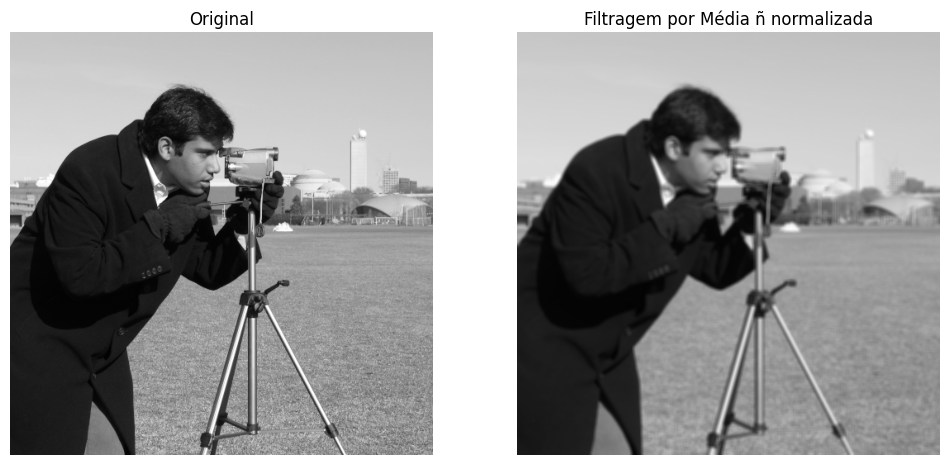

In [83]:
kernel = np.array([
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1]
])

# NORMALIZAÇÃO - MUITO IMPORTANTE
kernel = kernel/np.sum(kernel)

filtro_personalizado = cv2.filter2D(imagem, -1, kernel)
implot(imagem, filtro_personalizado, "Média ñ normalizada", kernel)

## Extra - Benchmark de Tempo: Métodos de Soma em Matrizes

fiquei curioso sobre como funciona o `np.sum(` e quis comparar com outros métodos nativos do python

In [84]:
import time

tamanho = 5000
matriz_teste = np.random.rand(tamanho, tamanho)

print(f"Matriz criada com dimensões: {matriz_teste.shape} ({matriz_teste.size:,} elementos)\n")

# sum(sum(matriz))
t_start = time.time()
soma_1 = sum(sum(matriz_teste))
t_end = time.time()
tempo_1 = t_end - t_start
print(f"sum(sum(matriz)): {tempo_1:.6f} segundos (Resultado: {soma_1:.4f})")

# np.sum(matriz)
t_start = time.time()
soma_2 = np.sum(matriz_teste)
t_end = time.time()
tempo_2 = t_end - t_start
print(f"np.sum(matriz): {tempo_2:.6f} segundos (Resultado: {soma_2:.4f})")

# matriz.ravel().sum()
t_start = time.time()
soma_3 = matriz_teste.ravel().sum()
t_end = time.time()
tempo_3 = t_end - t_start
print(f"matriz.ravel().sum(): {tempo_3:.6f} segundos (Resultado: {soma_3:.4f})")

Matriz criada com dimensões: (5000, 5000) (25,000,000 elementos)

sum(sum(matriz)): 0.027282 segundos (Resultado: 12499999.9955)
np.sum(matriz): 0.017436 segundos (Resultado: 12499999.9955)
matriz.ravel().sum(): 0.017280 segundos (Resultado: 12499999.9955)


In [85]:
print("\n--- Comparativo com %timeit (mais preciso para variações menores) ---")
print("1. sum(sum(matriz)):")
%timeit sum(sum(matriz_teste))

print("\n2. np.sum(matriz):")
%timeit np.sum(matriz_teste)

print("\n3. matriz.ravel().sum():")
%timeit matriz_teste.ravel().sum()


--- Comparativo com %timeit (mais preciso para variações menores) ---
1. sum(sum(matriz)):
27.3 ms ± 1.02 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)

2. np.sum(matriz):
18.7 ms ± 1.69 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)

3. matriz.ravel().sum():
17.6 ms ± 971 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


## 3 - Filtro Gaussiano Nativo

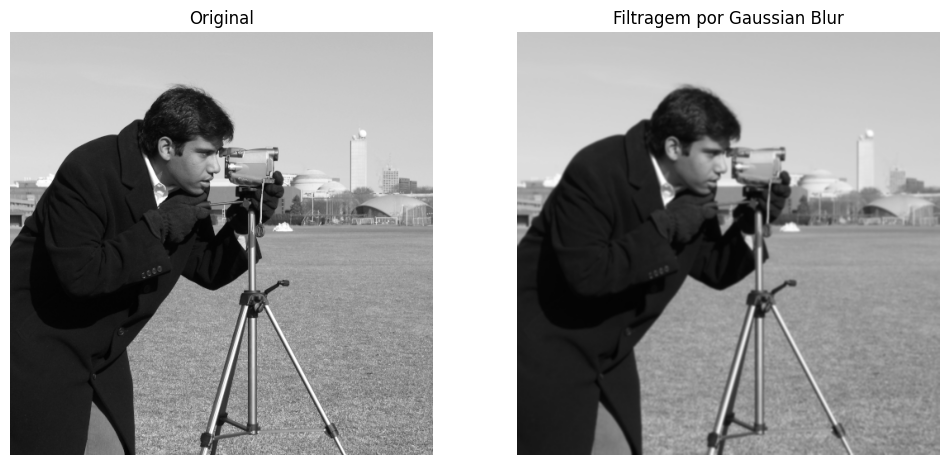

In [86]:
imagem_atenuada = cv2.GaussianBlur(imagem, (5, 5), 0)
implot(imagem, imagem_atenuada, "Gaussian Blur", (5, 5))

## 4 - Filtro de Nitidez

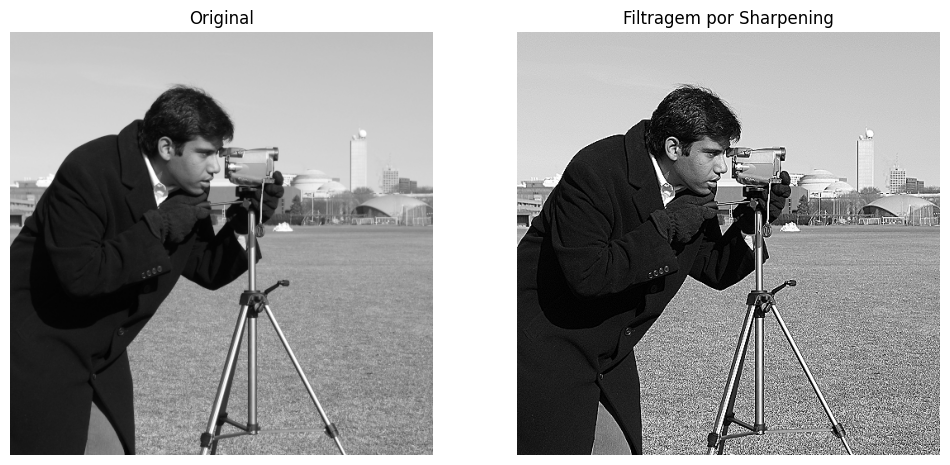

In [88]:
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

filtro_personalizado = cv2.filter2D(imagem, -1, kernel)
implot(imagem, filtro_personalizado, "Sharpening", '3x3')